# Explainable AI (XAI) Assignment: SHAP and LIME Implementation
In this notebook, we implement two prominent Explainable AI techniques—**SHAP (SHapley Additive exPlanations)** and **LIME (Local Interpretable Model-agnostic Explanations)**—to interpret predictions from a **Random Forest Classifier** trained on the Breast Cancer Wisconsin dataset.

In [1]:
# Install required XAI and machine learning libraries
!pip install -q shap lime scikit-learn matplotlib pandas numpy
print("Dependencies installed successfully!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dependencies installed successfully!


## 1. Dataset Loading and Preprocessing
We load the publicly available Breast Cancer dataset from `scikit-learn`. The dataset contains numerical features computed from digitized images of fine needle aspirates of breast masses, with binary targets (`0 = malignant`, `1 = benign`). We split the data into 80% training and 20% testing sets.

In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load dataset
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (455, 30)
Testing set shape: (114, 30)


## 2. Model Training (Random Forest Classifier)
We train an ensemble **Random Forest Classifier** with 100 estimators. Random Forests are powerful non-linear models that capture complex feature interactions, making them prime candidates for XAI analysis since their internal decision paths are non-trivial to inspect manually.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Train Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate performance
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Test Accuracy: {accuracy * 100:.2f}%")

Random Forest Test Accuracy: 96.49%


## 3. Global Interpretability using SHAP
**SHAP** applies cooperative game theory (Shapley values) to assign each feature an importance value for a particular prediction. We use `shap.TreeExplainer` optimized for tree-based models to compute global feature importance across the test set.

<Figure size 1000x600 with 0 Axes>

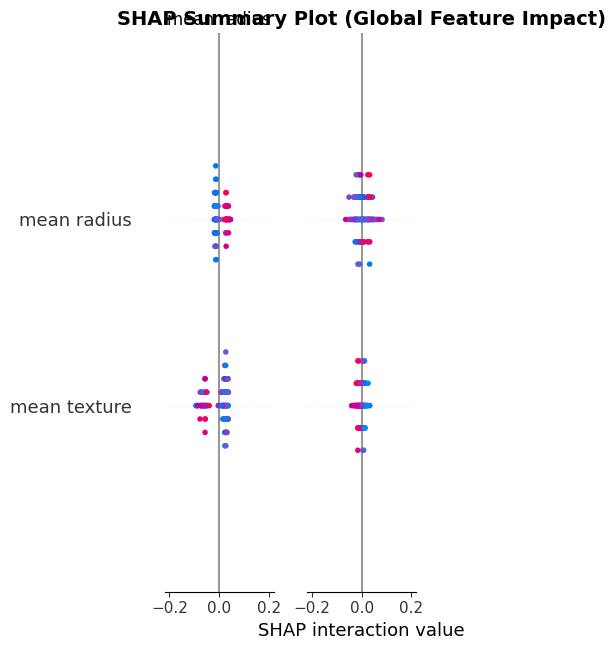

In [4]:
import shap
import matplotlib.pyplot as plt

# Compute SHAP values
explainer_shap = shap.TreeExplainer(model)
shap_values = explainer_shap(X_test)

# Generate SHAP Beeswarm Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Summary Plot (Global Feature Impact)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300)
plt.show()

## 4. Local Interpretability using LIME
While SHAP offers exact game-theoretic values, **LIME** explains individual predictions by perturbing input samples locally and fitting an interpretable surrogate model (like a linear regressor) around the prediction boundary. Below, we initialize the `LimeTabularExplainer` and analyze test sample index `0`.

In [5]:
import lime
import lime.lime_tabular
import numpy as np

# Initialize LIME Tabular Explainer
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=list(cancer.feature_names),
    class_names=list(cancer.target_names),
    mode='classification',
    random_state=42
)

# Select a specific test instance (e.g., index 0)
sample_idx = 0
sample_instance = X_test.iloc[sample_idx]

# Generate LIME local explanation
exp = explainer_lime.explain_instance(
    data_row=sample_instance,
    predict_fn=model.predict_proba,
    num_features=10
)

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

## 5. Visualizing Local Explanations (SHAP vs. LIME)
To compare how both frameworks explain a single decision, we render the **SHAP Waterfall Plot** alongside the **LIME Local Bar Plot** for the exact same test instance. This comparison highlights the methodological differences between exact Shapley attribution and local surrogate approximation.

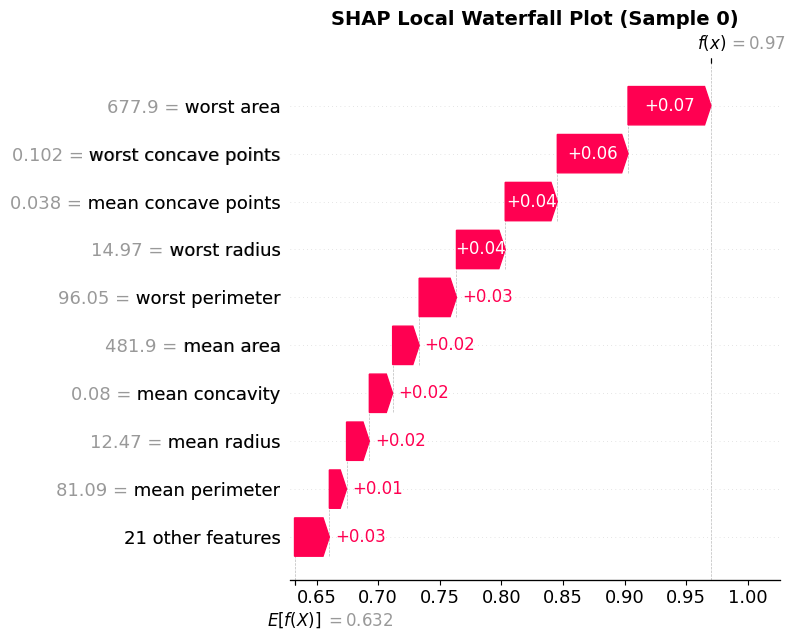

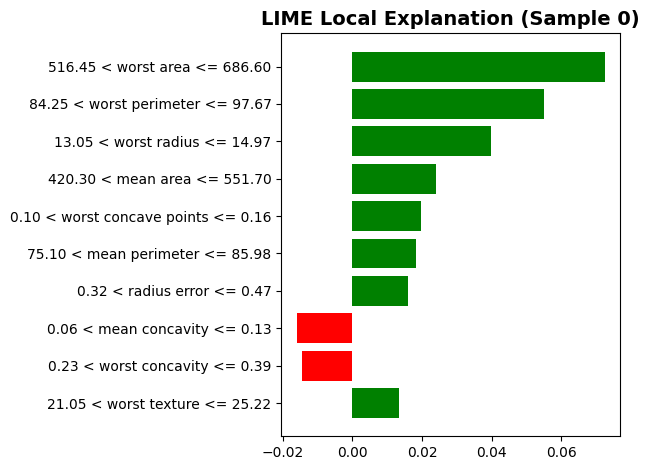

All visual plots rendered successfully and saved to disk!


In [6]:
# A. SHAP Waterfall Plot for Sample 0
plt.figure(figsize=(10, 6))
# Handle multi-dimensional SHAP output structure for binary classification
shap_val_instance = shap_values[sample_idx, :, 1] if len(shap_values.shape) == 3 else shap_values[sample_idx]
shap.plots.waterfall(shap_val_instance, show=False)
plt.title(f"SHAP Local Waterfall Plot (Sample {sample_idx})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=300)
plt.show()

# B. LIME Local Explanation Plot for Sample 0
fig = exp.as_pyplot_figure()
plt.title(f"LIME Local Explanation (Sample {sample_idx})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("lime_local.png", dpi=300)
plt.show()

print("All visual plots rendered successfully and saved to disk!")